# Basic basic spike sorting

* K-means
* Gaussian mixture models

In [6]:
from sklearn.manifold import TSNE

In [7]:
import cPickle as pickle
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sparse
from sklearn.decomposition import PCA
from sklearn.mixture import BayesianGaussianMixture
from sklearn.cluster import KMeans, SpectralClustering

from neo.core import SpikeTrain, Unit, Segment, Block, ChannelIndex

from spikes.plotting import plot_waveform_overlay

from config import config

%load_ext autoreload
%autoreload 2

In [14]:
BIRD = "LbY6074__161215_145633"
ELEC = 5

In [9]:
DATADIR = config.get("project", "datadir")
data_path = os.path.join(DATADIR, "birds", "LbY6074", "RHD", "{}-thresholded.pkl".format(BIRD))
# ../../data/birds/LbY6074/RHD/LbY6074__161215_145633.

In [10]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [12]:
from spikes.sorting.preprocess import binned_spikes, collect_waveforms

In [15]:
unit = (
    channel_index.units[0]
    for channel_index in block.channel_indexes
    if channel_index.name == "Amp Elec {}".format(ELEC)
).next()

# Assumes we want to slice the middle 32 time-points of the waveforms
waveforms = collect_waveforms(unit.spiketrains, threshold=-70)[0][:, 8:40]


In [16]:
waveforms = waveforms[np.max(np.abs(waveforms), axis=1) < 300]


In [17]:
pca = PCA(n_components=10)
x = pca.fit_transform(waveforms)

In [18]:
def comparator(x, y, tsne=False):
    if tsne:
        pca = TSNE(n_components=2)
    else:
        pca = PCA(n_components=2)
    x_pca = pca.fit_transform(x)
    
    labels = np.unique(y)
    
    plt.figure(figsize=(5, 5))
    for label in labels:# sorted(labels, key=lambda l: np.sum(y == l)):
        plt.scatter(x_pca[y == label].T[0], x_pca[y == label].T[1], s=1, label=label)
    plt.legend()    
        
    plt.figure()
    for label in labels:# sorted(labels, key=lambda l: np.sum(y == l)):
        plt.plot(np.mean(x[y == label], axis=0), label=label)
    plt.legend()

## K-means

In [48]:
k_means_model = KMeans(n_clusters=16)
k_means_model.fit(waveforms)

KMeans(algorithm='auto', copy_x=True, init='k-means++', max_iter=300,
    n_clusters=16, n_init=10, n_jobs=1, precompute_distances='auto',
    random_state=None, tol=0.0001, verbose=0)

In [49]:
y = k_means_model.predict(waveforms)

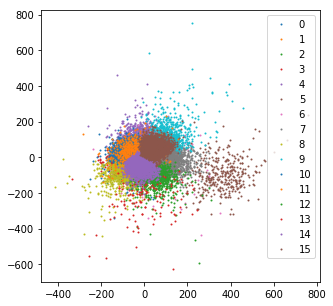

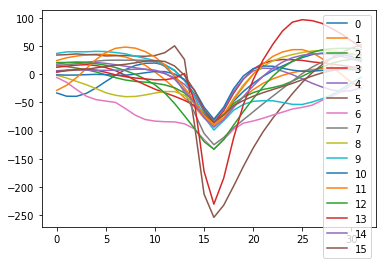

In [50]:
comparator(waveforms, y)
plt.show()

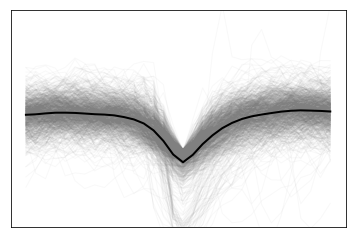

In [22]:
plot_waveform_overlay(waveforms[:1000], alpha=0.05)
plt.ylim(-250, 250)
plt.xticks([])
plt.yticks([])
plt.show()

In [23]:
mixture_model = BayesianGaussianMixture(n_components=8, weight_concentration_prior=0.1)
mixture_model.fit(waveforms)

/auto/fhome/kevin/Projects/songephys/env/local/lib/python2.7/site-packages/sklearn/mixture/base.py:237: ConvergenceWarning: Initialization 1 did not converged. Try different init parameters, or increase max_iter, tol or check for degenerate data.
  % (init + 1), ConvergenceWarning)


BayesianGaussianMixture(covariance_prior=None, covariance_type='full',
            degrees_of_freedom_prior=None, init_params='kmeans',
            max_iter=100, mean_precision_prior=None, mean_prior=None,
            n_components=8, n_init=1, random_state=None, reg_covar=1e-06,
            tol=0.001, verbose=0, verbose_interval=10, warm_start=False,
            weight_concentration_prior=0.1,
            weight_concentration_prior_type='dirichlet_process')

In [24]:
y = mixture_model.predict(waveforms)

In [25]:
np.unique(y, return_counts=True)

(array([0, 1, 2, 3, 4, 5, 6, 7]),
 array([2869, 2732,  531, 1241, 2162, 3106,  278, 5983]))

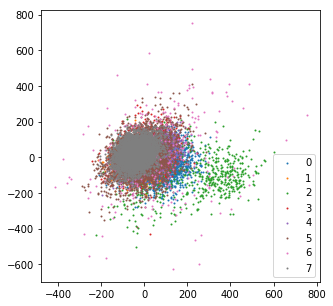

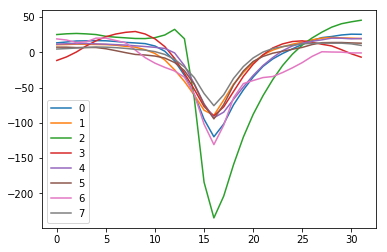

In [26]:
comparator(waveforms, y)
plt.show()

Okay, at this point it seeeems like K-means might work better. For this unit at least.

In [27]:
xy = TSNE(n_components=2).fit_transform(x[:10000])

In [28]:
np.save("../../../spikes-vis/data/spikes/{}-e{}/2d.npy".format(BIRD, ELEC), xy)

In [51]:
np.save("../../../spikes-vis/data/spikes/{}-e{}/waveforms.npy".format(BIRD, ELEC), waveforms[:10000])

In [52]:
np.save("../../../spikes-vis/data/spikes/{}-e{}/clusters.npy".format(BIRD, ELEC), y[:10000].astype(np.int64))